In [1]:

print("Hello, Machine Learning!")
print("학생 성적 예측 프로젝트를 시작합니다.")


Hello, Machine Learning!
학생 성적 예측 프로젝트를 시작합니다.


In [3]:

import pandas as pd
import urllib.request
import zipfile
import io

# 1. UCI 데이터셋 다운로드
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = urllib.request.urlopen(url)
outer_zip = zipfile.ZipFile(io.BytesIO(response.read()))

# 2. 내부 ZIP 파일 열기
inner_zip = zipfile.ZipFile(
    io.BytesIO(outer_zip.read("student.zip"))
)

# 3. 수학 성적 데이터 불러오기
df = pd.read_csv(
    inner_zip.open("student-mat.csv"),
    sep=";"
)

# 4. 데이터 확인
print("데이터 불러오기 성공!")
print("데이터 크기:", df.shape)

display(df.head())


데이터 불러오기 성공!
데이터 크기: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:

# 데이터의 기본 정보 확인
print("=== 데이터 기본 정보 ===")
df.info()

# 결측치 확인
print("\n=== 결측치 개수 ===")
print(df.isnull().sum())

# 중복 데이터 확인
print("\n=== 중복 행 개수 ===")
print(df.duplicated().sum())


=== 데이터 기본 정보 ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    obje

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


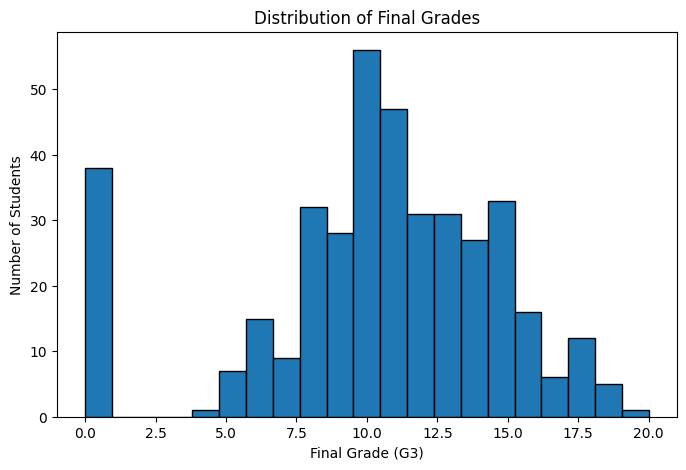

In [5]:

import matplotlib.pyplot as plt

# 최종 성적의 기초 통계
print(df["G3"].describe())

# 최종 성적 분포 시각화
plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=21, edgecolor="black")

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()


=== 공부 시간별 평균 최종 성적 ===
studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


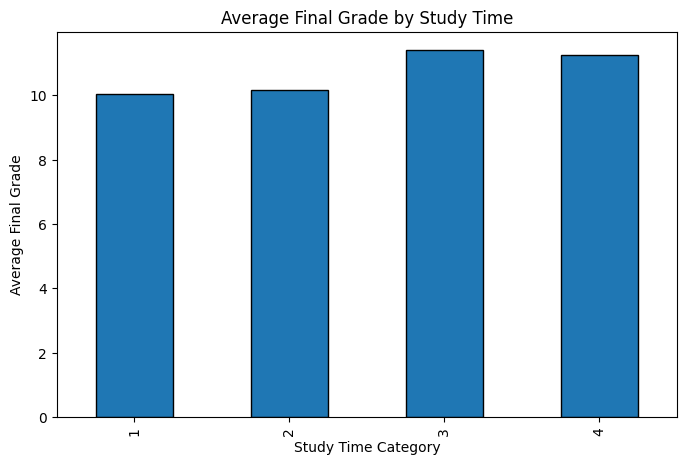

In [6]:

# 공부 시간별 최종 성적 평균
study_result = df.groupby("studytime")["G3"].mean()

print("=== 공부 시간별 평균 최종 성적 ===")
print(study_result)

# 그래프 그리기
plt.figure(figsize=(8, 5))
study_result.plot(kind="bar", edgecolor="black")

plt.title("Average Final Grade by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")

plt.show()


In [7]:

from sklearn.model_selection import train_test_split

# 입력 변수(X)와 예측할 값(y) 분리
X = df.drop(columns=["G3"])
y = df["G3"]

# 전체 데이터의 15%를 테스트 데이터로 분리
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42
)

# 남은 데이터에서 검증 데이터 분리
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.15 / 0.85,
    random_state=42
)

print("학습 데이터:", X_train.shape)
print("검증 데이터:", X_val.shape)
print("테스트 데이터:", X_test.shape)


학습 데이터: (275, 32)
검증 데이터: (60, 32)
테스트 데이터: (60, 32)


In [8]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 숫자형 변수와 문자형 변수 구분
numeric_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# 숫자형 데이터 전처리
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 문자형 데이터 전처리
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 전처리 통합
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# 학습 데이터로만 전처리 기준 학습
X_train_processed = preprocessor.fit_transform(X_train)

# 검증·테스트 데이터에는 같은 기준 적용
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("전처리 완료!")
print("전처리 전:", X_train.shape)
print("전처리 후:", X_train_processed.shape)


전처리 완료!
전처리 전: (275, 32)
전처리 후: (275, 58)


In [9]:

import numpy as np

# 전처리된 데이터를 DataFrame으로 변환
feature_names = preprocessor.get_feature_names_out()

X_train_after = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names
)

print("=== 전처리 전 데이터 ===")
display(X_train.head())

print("\n=== 전처리 후 데이터 ===")
display(X_train_after.head())

print("\n전처리 전 변수 개수:", X_train.shape[1])
print("전처리 후 변수 개수:", X_train_after.shape[1])

print("\n전처리 후 결측치 개수:")
print(X_train_after.isnull().sum().sum())


=== 전처리 전 데이터 ===


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
299,GP,M,18,U,LE3,T,4,4,teacher,teacher,...,yes,1,4,2,2,2,1,5,16,15
111,GP,F,16,R,GT3,T,3,3,services,other,...,no,4,1,2,1,1,2,0,7,10
174,GP,F,16,U,LE3,T,3,3,other,other,...,no,4,4,5,1,1,4,4,10,11
319,GP,F,18,U,GT3,T,4,4,teacher,other,...,no,4,4,4,3,3,5,2,11,11
144,GP,M,17,U,GT3,T,2,1,other,other,...,no,5,4,5,1,2,5,0,5,0



=== 전처리 후 데이터 ===


,num__age,num__Medu,num__Fedu,num__traveltime,num__studytime,num__failures,num__famrel,num__freetime,num__goout,num__Dalc,...,cat__activities_no,cat__activities_yes,cat__nursery_no,cat__nursery_yes,cat__higher_no,cat__higher_yes,cat__internet_no,cat__internet_yes,cat__romantic_no,cat__romantic_yes
0,1.001126,1.127320,1.424276,-0.605691,-1.238823,-0.464195,-3.406096,0.790009,-1.062836,0.596956,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
1,-0.567590,0.220849,0.480479,-0.605691,1.168784,0.851821,0.037567,-2.172523,-1.062836,-0.535202,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
2,-0.567590,0.220849,0.480479,0.868336,-0.035020,-0.464195,0.037567,0.790009,1.677287,-0.535202,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
3,1.001126,1.127320,1.424276,-0.605691,-0.035020,-0.464195,0.037567,0.790009,0.763913,1.729113,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
4,0.216768,-0.685622,-1.407116,-0.605691,-1.238823,3.483852,1.185455,0.790009,1.677287,-0.535202,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0



전처리 전 변수 개수: 32
전처리 후 변수 개수: 58

전처리 후 결측치 개수:
0


In [10]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 첫 번째 모델 생성
dt_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

# 모델 학습
dt_model.fit(X_train_processed, y_train)

# 검증 데이터 예측
dt_pred = dt_model.predict(X_val_processed)

# 성능 평가
dt_mae = mean_absolute_error(y_val, dt_pred)
dt_rmse = np.sqrt(mean_squared_error(y_val, dt_pred))

print("=== 의사결정나무 학습 완료 ===")
print("MAE:", round(dt_mae, 3))
print("RMSE:", round(dt_rmse, 3))


=== 의사결정나무 학습 완료 ===
MAE: 1.092
RMSE: 2.175


In [11]:

from sklearn.ensemble import RandomForestRegressor

# 두 번째 모델 생성
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

# 모델 학습
rf_model.fit(X_train_processed, y_train)

# 검증 데이터 예측
rf_pred = rf_model.predict(X_val_processed)

# 성능 평가
rf_mae = mean_absolute_error(y_val, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_pred))

print("=== 랜덤 포레스트 학습 완료 ===")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))


=== 랜덤 포레스트 학습 완료 ===
MAE: 1.03
RMSE: 1.666


In [12]:

import pandas as pd

# 모델 성능 비교표
results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "MAE": [dt_mae, rf_mae],
    "RMSE": [dt_rmse, rf_rmse]
})

print("=== 모델 성능 비교 (Validation) ===")
display(results.round(3))

# MAE 기준으로 우수한 모델 확인
best_model_name = results.loc[
    results["MAE"].idxmin(), "Model"
]

print("MAE 기준 우수 모델:", best_model_name)


=== 모델 성능 비교 (Validation) ===


,Model,MAE,RMSE
0,Decision Tree,1.092,2.175
1,Random Forest,1.030,1.666


MAE 기준 우수 모델: Random Forest


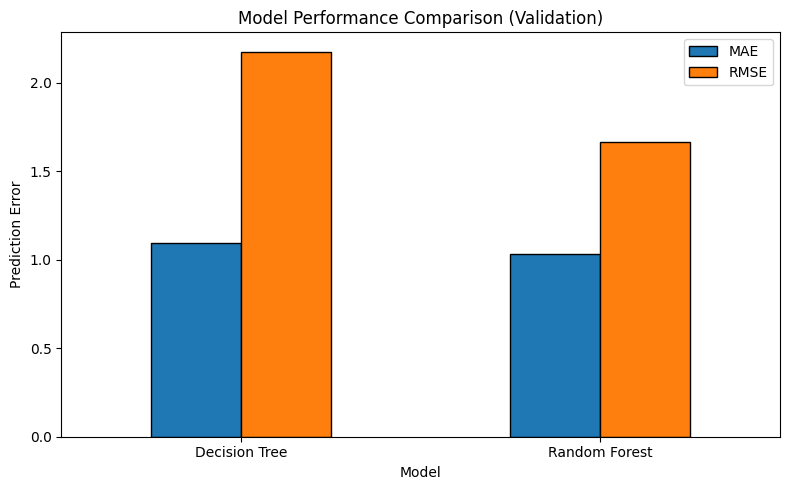

In [13]:

import matplotlib.pyplot as plt

# 모델별 MAE와 RMSE 비교
results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Model Performance Comparison (Validation)")
plt.xlabel("Model")
plt.ylabel("Prediction Error")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [14]:

# 실제 성적과 예측 성적 비교
comparison = pd.DataFrame({
    "Actual Grade": y_val.to_numpy(),
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred
})

print("=== 실제 성적과 예측 성적 비교 ===")
display(comparison.head(10).round(2))


=== 실제 성적과 예측 성적 비교 ===


,Actual Grade,Decision Tree,Random Forest
0,14,14.75,14.30
1,13,14.75,14.24
2,0,0.00,2.33
3,12,11.83,11.39
4,8,8.40,7.56
5,13,11.83,11.69
6,9,8.25,5.75
7,18,18.14,18.27
8,7,6.33,6.62
9,6,0.00,2.19


In [15]:

print("===== 모델 성능 비교 =====")

print("\n[1] 의사결정나무")
print("MAE :", round(dt_mae, 3))
print("RMSE:", round(dt_rmse, 3))

print("\n[2] 랜덤 포레스트")
print("MAE :", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))


===== 모델 성능 비교 =====

[1] 의사결정나무
MAE : 1.092
RMSE: 2.175

[2] 랜덤 포레스트
MAE : 1.03
RMSE: 1.666


In [16]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

# 여러 설정을 비교할 목록
settings = [
    (50, 3),
    (100, 5),
    (100, 8),
    (200, 5),
    (200, 8)
]

tuning_results = []

for n_trees, depth in settings:

    model = RandomForestRegressor(
        n_estimators=n_trees,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_val_processed)

    mae = mean_absolute_error(y_val, predictions)

    tuning_results.append({
        "n_estimators": n_trees,
        "max_depth": depth,
        "MAE": mae
    })

tuning_df = pd.DataFrame(tuning_results)

print("=== 랜덤 포레스트 설정별 성능 ===")
display(tuning_df.round(3))


=== 랜덤 포레스트 설정별 성능 ===


,n_estimators,max_depth,MAE
0,50,3,1.073
1,100,5,1.030
2,100,8,1.000
3,200,5,1.013
4,200,8,0.983


In [17]:

# MAE가 가장 낮은 설정 찾기
best_row = tuning_df.loc[tuning_df["MAE"].idxmin()]

best_n = int(best_row["n_estimators"])
best_depth = int(best_row["max_depth"])

print("=== 선택된 설정 ===")
print("나무 개수:", best_n)
print("최대 깊이:", best_depth)
print("Validation MAE:", round(best_row["MAE"], 3))

# 선택한 설정으로 모델 학습
best_rf_model = RandomForestRegressor(
    n_estimators=best_n,
    max_depth=best_depth,
    random_state=42,
    n_jobs=-1
)

best_rf_model.fit(X_train_processed, y_train)

# 검증 데이터 예측
best_rf_pred = best_rf_model.predict(X_val_processed)

print("최종 후보 모델 학습 완료!")


=== 선택된 설정 ===
나무 개수: 200
최대 깊이: 8
Validation MAE: 0.983
최종 후보 모델 학습 완료!


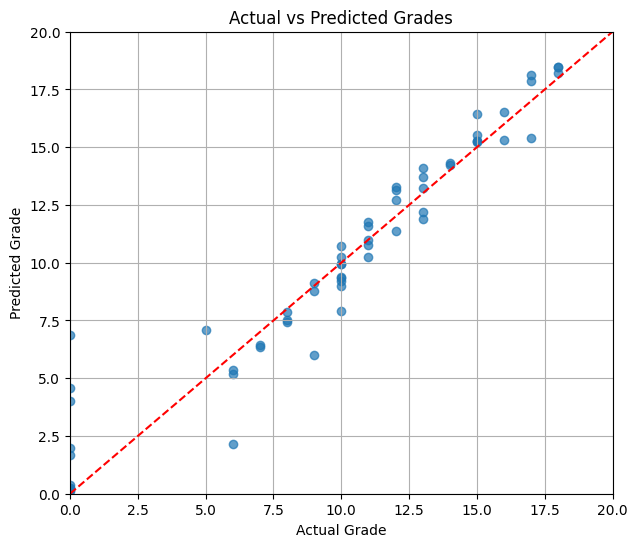

In [18]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    y_val,
    best_rf_pred,
    alpha=0.7
)

# 완벽한 예측을 의미하는 기준선
plt.plot([0, 20], [0, 20], "r--")

plt.xlabel("Actual Grade")
plt.ylabel("Predicted Grade")
plt.title("Actual vs Predicted Grades")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.grid(True)
plt.show()


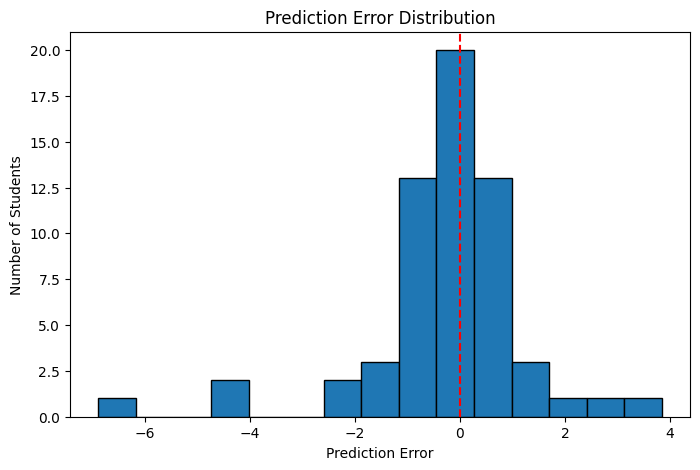

평균 오차: -0.25
최대 절대 오차: 6.888


In [19]:

import numpy as np

errors = y_val.to_numpy() - best_rf_pred

plt.figure(figsize=(8, 5))
plt.hist(errors, bins=15, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Prediction Error")
plt.ylabel("Number of Students")
plt.title("Prediction Error Distribution")
plt.show()

print("평균 오차:", round(np.mean(errors), 3))
print("최대 절대 오차:", round(np.max(np.abs(errors)), 3))


In [20]:

error_df = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Predicted": best_rf_pred,
    "Absolute Error": np.abs(errors)
})

# 오차가 큰 순서로 정렬
error_df = error_df.sort_values(
    "Absolute Error",
    ascending=False
)

print("=== 오차가 가장 큰 학생 5명 ===")
display(error_df.head(5).round(2))


=== 오차가 가장 큰 학생 5명 ===


,Actual,Predicted,Absolute Error
31,0,6.89,6.89
36,0,4.59,4.59
50,0,4.03,4.03
9,6,2.15,3.85
6,9,6.02,2.98


In [21]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# 테스트 데이터로 예측
dt_test_pred = dt_model.predict(X_test_processed)
rf_test_pred = best_rf_model.predict(X_test_processed)

# 평가 함수
def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

# 모델별 테스트 결과
dt_scores = evaluate_model(y_test, dt_test_pred)
rf_scores = evaluate_model(y_test, rf_test_pred)

test_results = pd.DataFrame(
    [dt_scores, rf_scores],
    index=["Decision Tree", "Random Forest"]
)

print("=== 최종 테스트 성능 비교 ===")
display(test_results.round(3))


=== 최종 테스트 성능 비교 ===


,MAE,RMSE,R2
Decision Tree,1.273,2.443,0.730
Random Forest,1.209,2.122,0.796


### 최종 모델 평가 및 선정 근거

본 프로젝트에서는 학생의 최종 성적(G3)을 예측하기 위해 의사결정나무(Decision Tree)와 랜덤 포레스트(Random Forest) 회귀 모델을 직접 학습하고 성능을 비교하였다.

테스트 데이터 평가 결과, 의사결정나무는 MAE 1.273, RMSE 2.443, R² 0.730을 기록하였으며, 랜덤 포레스트는 MAE 1.209, RMSE 2.122, R² 0.796을 기록하였다.

랜덤 포레스트는 의사결정나무 대비 MAE를 약 5.0%, RMSE를 약 13.1% 감소시켰으며, R²도 0.066p 높게 나타났다.

이는 여러 의사결정나무의 예측을 결합하는 앙상블 방식이 본 데이터셋에서 단일 의사결정나무보다 우수한 일반화 성능을 보였음을 시사한다.

따라서 본 프로젝트에서는 세 가지 평가 지표에서 모두 우수한 성능을 기록한 랜덤 포레스트를 최종 모델로 선정하였다.

In [22]:

import joblib

# 최종 선정한 랜덤 포레스트 저장
joblib.dump(best_rf_model, "student_model.pkl")

# 전처리 도구 저장
joblib.dump(preprocessor, "preprocessor.pkl")

# 모델이 요구하는 입력 변수 목록 저장
joblib.dump(X_train.columns.tolist(), "feature_columns.pkl")

print("모델 저장 완료!")


모델 저장 완료!


In [23]:

from google.colab import files

files.download("student_model.pkl")
files.download("preprocessor.pkl")
files.download("feature_columns.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:

import joblib

# 학습 데이터에서 대표값 계산
default_values = {}

for col in X_train.columns:
    if X_train[col].dtype == "object":
        default_values[col] = X_train[col].mode()[0]
    else:
        default_values[col] = float(X_train[col].median())

# 기본값 파일 저장
joblib.dump(default_values, "default_values.pkl")

print("기본값 파일 생성 완료!")
print("변수 개수:", len(default_values))


기본값 파일 생성 완료!
변수 개수: 32


In [25]:

from google.colab import files

files.download("default_values.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:

import sys
import sklearn
import joblib
import numpy
import pandas

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)


Python: 3.13.18
scikit-learn: 1.6.1
joblib: 1.6.0
numpy: 2.4.6
pandas: 2.2.3


In [27]:

import sys
import sklearn
import joblib
import numpy
import pandas

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)


Python: 3.13.18
scikit-learn: 1.6.1
joblib: 1.6.0
numpy: 2.4.6
pandas: 2.2.3


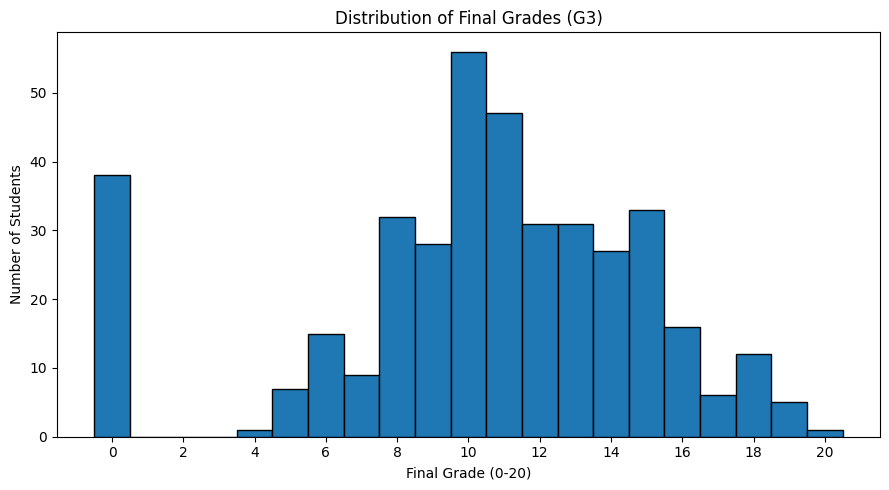

그래프 저장 완료!


In [28]:

import matplotlib.pyplot as plt
import numpy as np

# 최종 성적 분포 그래프
plt.figure(figsize=(9, 5))

plt.hist(
    df["G3"],
    bins=np.arange(-0.5, 21.5, 1),
    edgecolor="black"
)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade (0-20)")
plt.ylabel("Number of Students")
plt.xticks(range(0, 21, 2))

plt.tight_layout()

# 그래프 이미지 저장
plt.savefig("grade_distribution.png", dpi=300)

plt.show()

print("그래프 저장 완료!")


In [30]:

from google.colab import files

files.download("grade_distribution.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:

print("전체 학생 수:", len(df))
print("평균 성적:", round(df["G3"].mean(), 2))
print("중앙값:", df["G3"].median())
print("최저 성적:", df["G3"].min())
print("최고 성적:", df["G3"].max())

print("0~5점:", ((df["G3"] >= 0) & (df["G3"] <= 5)).sum())
print("6~10점:", ((df["G3"] >= 6) & (df["G3"] <= 10)).sum())
print("11~15점:", ((df["G3"] >= 11) & (df["G3"] <= 15)).sum())
print("16~20점:", ((df["G3"] >= 16) & (df["G3"] <= 20)).sum())


전체 학생 수: 395
평균 성적: 10.42
중앙값: 11.0
최저 성적: 0
최고 성적: 20
0~5점: 46
6~10점: 140
11~15점: 169
16~20점: 40


In [32]:

import pandas as pd
import numpy as np

# 전처리 전 데이터
before = X_train.copy()

# 전처리 후 데이터
after = X_train_after.copy()

# 전처리 전후 비교표
comparison_table = pd.DataFrame({
    "항목": [
        "데이터 수",
        "변수 개수",
        "결측치 개수",
        "문자형 변수 개수",
        "숫자형 변수 개수"
    ],
    "전처리 전": [
        before.shape[0],
        before.shape[1],
        before.isnull().sum().sum(),
        len(before.select_dtypes(include=["object"]).columns),
        len(before.select_dtypes(include=["number"]).columns)
    ],
    "전처리 후": [
        after.shape[0],
        after.shape[1],
        after.isnull().sum().sum(),
        len(after.select_dtypes(include=["object"]).columns),
        len(after.select_dtypes(include=["number"]).columns)
    ]
})

print("=== 데이터 전처리 전후 비교 ===")
display(comparison_table)


=== 데이터 전처리 전후 비교 ===


,항목,전처리 전,전처리 후
0,데이터 수,275,275
1,변수 개수,32,58
2,결측치 개수,0,0
3,문자형 변수 개수,17,0
4,숫자형 변수 개수,15,58


In [33]:

# 표준화 전후 비교
scaling_comparison = pd.DataFrame({
    "전처리 전 결석 횟수": X_train["absences"].head(5).values,
    "전처리 후 결석 횟수": X_train_after["num__absences"].head(5).values
})

print("=== 결석 횟수 표준화 전후 ===")
display(scaling_comparison.round(3))


=== 결석 횟수 표준화 전후 ===


,전처리 전 결석 횟수,전처리 후 결석 횟수
0,5,-0.137
1,0,-0.711
2,4,-0.251
3,2,-0.481
4,0,-0.711


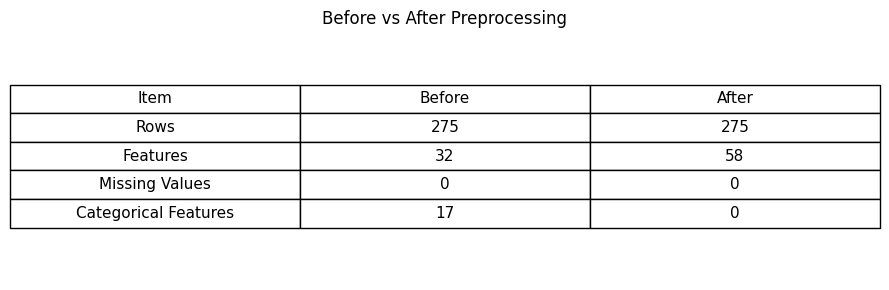

이미지 저장 완료!


In [34]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3))
ax.axis("off")

# 한글 폰트 문제를 피하기 위해 영문 표 사용
table_data = [
    ["Rows", before.shape[0], after.shape[0]],
    ["Features", before.shape[1], after.shape[1]],
    ["Missing Values",
     before.isnull().sum().sum(),
     after.isnull().sum().sum()],
    ["Categorical Features",
     len(before.select_dtypes(include=["object"]).columns),
     len(after.select_dtypes(include=["object"]).columns)]
]

table = ax.table(
    cellText=table_data,
    colLabels=["Item", "Before", "After"],
    loc="center",
    cellLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.6)

plt.title("Before vs After Preprocessing")
plt.tight_layout()

plt.savefig(
    "preprocessing_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("이미지 저장 완료!")


In [35]:

from google.colab import files

files.download("preprocessing_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:

print("=== 최종 랜덤 포레스트 설정 ===")

print("최종 나무 개수:", best_n)
print("최종 최대 깊이:", best_depth)

print("\n=== 하이퍼파라미터별 성능 비교 ===")
display(tuning_df.round(3))


=== 최종 랜덤 포레스트 설정 ===
최종 나무 개수: 200
최종 최대 깊이: 8

=== 하이퍼파라미터별 성능 비교 ===


,n_estimators,max_depth,MAE
0,50,3,1.073
1,100,5,1.030
2,100,8,1.000
3,200,5,1.013
4,200,8,0.983


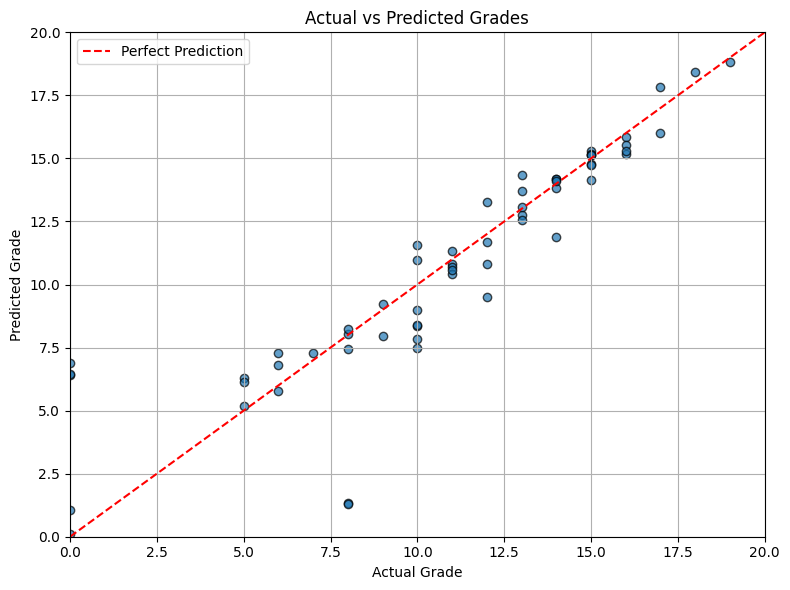

첫 번째 그래프 저장 완료!


In [37]:

import matplotlib.pyplot as plt

# 실제 성적과 AI 예측 성적
actual = y_test.to_numpy()
predicted = rf_test_pred

plt.figure(figsize=(8, 6))

plt.scatter(
    actual,
    predicted,
    alpha=0.7,
    edgecolors="black"
)

# 예측이 정확히 일치하는 기준선
plt.plot(
    [0, 20], [0, 20],
    "r--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Grades")
plt.xlabel("Actual Grade")
plt.ylabel("Predicted Grade")

plt.xlim(0, 20)
plt.ylim(0, 20)
plt.legend()
plt.grid(True)
plt.tight_layout()

# 이미지 저장
plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()

print("첫 번째 그래프 저장 완료!")


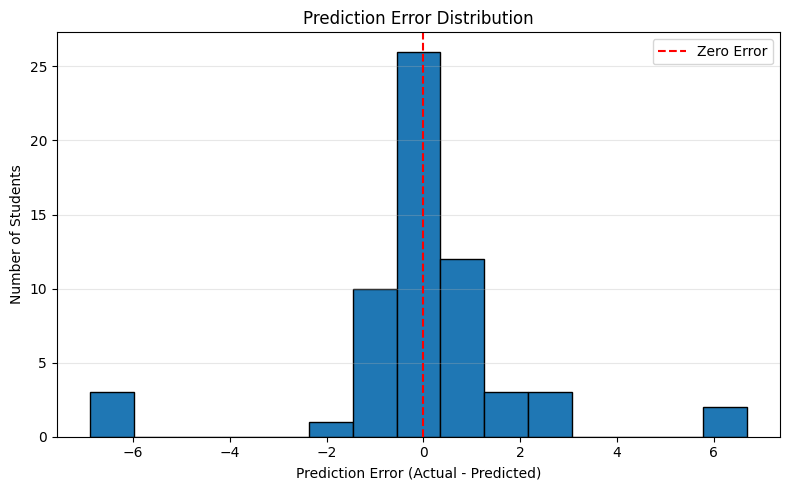

두 번째 그래프 저장 완료!


In [38]:

import numpy as np
import matplotlib.pyplot as plt

# 실제 성적 - 예측 성적
errors = actual - predicted

plt.figure(figsize=(8, 5))

plt.hist(
    errors,
    bins=15,
    edgecolor="black"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Number of Students")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# 이미지 저장
plt.savefig(
    "prediction_error_distribution.png",
    dpi=300
)

plt.show()

print("두 번째 그래프 저장 완료!")


In [40]:

from google.colab import files

files.download("actual_vs_predicted.png")
files.download("prediction_error_distribution.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:

import pandas as pd
import numpy as np

# 테스트 학생의 실제 정보와 예측 결과 합치기
error_cases = X_test[
    ["G1", "G2", "studytime", "absences", "failures"]
].copy()

error_cases["실제 최종 성적"] = y_test
error_cases["AI 예측 성적"] = rf_test_pred

# 절대 오차 계산
error_cases["절대 오차"] = np.abs(
    error_cases["실제 최종 성적"]
    - error_cases["AI 예측 성적"]
)

# 오차가 큰 학생 5명
top_errors = error_cases.sort_values(
    "절대 오차",
    ascending=False
).head(5)

print("=== 예측 오차가 가장 큰 학생 5명 ===")
display(top_errors.round(2))


=== 예측 오차가 가장 큰 학생 5명 ===


,G1,G2,studytime,absences,failures,실제 최종 성적,AI 예측 성적,절대 오차
334,10,9,4,0,0,0,6.90,6.90
90,7,7,3,0,0,8,1.31,6.69
124,8,7,2,0,0,8,1.32,6.68
140,7,9,4,0,0,0,6.45,6.45
316,8,8,2,0,0,0,6.39,6.39
